# Jour 1 — Préparation et exploration des données

**Projet final « Apprentissage non supervisé » — Segmentation de clientèle bancaire**
Master BDA/IA — Ndeye Sokhna Nokho

**Objectif du jour (Chapitre 1)** : passer du fichier brut à des données prêtes pour le clustering.

| Étape | Contenu |
|---|---|
| 1 | Chargement et description de la matrice de données, types de variables |
| 2 | Nettoyage : `unknown`, doublons, valeurs aberrantes |
| 3 | Analyse exploratoire (EDA) |
| 4 | Choix des variables actives / illustratives |
| 5 | Deux représentations : (a) one-hot + standardisation, (b) données mixtes |
| 6 | Échantillon stratifié de 4 000 clients |
| 7 | Réduction de dimension : PCA, t-SNE, UMAP |

> **Règle du projet** : la variable `y` (souscription) n'est **jamais** utilisée pour construire les clusters. Elle ne sert que de vérité terrain au Jour 4.

> Ce notebook fait partie d'une série de huit (un par étape du projet). Les huit sont aussi réunis, dans l'ordre, dans `projet_complet.ipynb`.

In [1]:
# Mise en forme : toutes les bordures sur tous les tableaux du notebook
from IPython.display import HTML, display
display(HTML("<style>table, th, td {border: 1px solid #333 !important; border-collapse: collapse !important;} th, td {padding: 4px 8px !important;}</style>"))

In [2]:
import sys, warnings
sys.path.append("..")            # pour importer le dossier src/
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

from src.config import SEED, N_SAMPLE, DATA_PATH, FIG, TAB, OUT
from src import preprocessing as pp

np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)

Matplotlib is building the font cache; this may take a moment.


## 1. Chargement et description de la matrice de données

In [3]:
df_raw = pp.load_raw(DATA_PATH)
print(f"Matrice de données : {df_raw.shape[0]} individus (clients) x {df_raw.shape[1]} variables")
df_raw.head()

Matrice de données : 41188 individus (clients) x 21 variables


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Chaque **ligne** est un contact téléphonique avec un client, chaque **colonne** une variable : 20 variables descriptives + la cible `y`.

### Types de variables
Le type statistique d'une variable détermine la distance qu'on a le droit d'utiliser dessus (Chapitre 2). On les classe donc soigneusement.

In [4]:
types = pd.DataFrame([
    ("age",            "quantitative discrète",  "client",    "âge en années"),
    ("job",            "qualitative nominale",   "client",    "profession (12 modalités)"),
    ("marital",        "qualitative nominale",   "client",    "statut marital"),
    ("education",      "qualitative ordinale",   "client",    "niveau d'études"),
    ("default",        "binaire (+ unknown)",    "client",    "crédit en défaut ?"),
    ("housing",        "binaire",                "client",    "prêt immobilier ?"),
    ("loan",           "binaire",                "client",    "prêt personnel ?"),
    ("contact",        "binaire",                "campagne",  "canal : cellular / telephone"),
    ("month",          "qualitative ordinale",   "campagne",  "mois du dernier contact"),
    ("day_of_week",    "qualitative ordinale",   "campagne",  "jour du dernier contact"),
    ("duration",       "quantitative continue",  "campagne",  "durée du dernier appel (s)"),
    ("campaign",       "quantitative discrète",  "campagne",  "nb de contacts pendant cette campagne"),
    ("pdays",          "quantitative discrète",  "historique","jours depuis le dernier contact (999 = jamais)"),
    ("previous",       "quantitative discrète",  "historique","nb de contacts avant cette campagne"),
    ("poutcome",       "qualitative nominale",   "historique","résultat de la campagne précédente"),
    ("emp.var.rate",   "quantitative continue",  "contexte",  "taux de variation de l'emploi"),
    ("cons.price.idx", "quantitative continue",  "contexte",  "indice des prix à la consommation"),
    ("cons.conf.idx",  "quantitative continue",  "contexte",  "indice de confiance des ménages"),
    ("euribor3m",      "quantitative continue",  "contexte",  "taux Euribor 3 mois"),
    ("nr.employed",    "quantitative continue",  "contexte",  "nombre d'employés (milliers)"),
    ("y",              "binaire",                "cible",     "souscription au dépôt à terme (vérité terrain)"),
], columns=["variable", "type statistique", "famille", "description"])
types["nb valeurs distinctes"] = [df_raw[v].nunique() for v in types["variable"]]
types.to_csv(TAB / "01_types_variables.csv", index=False)
types

,variable,type statistique,famille,description,nb valeurs distinctes
0,age,quantitative discrète,client,âge en années,78
1,job,qualitative nominale,client,profession (12 modalités),12
2,marital,qualitative nominale,client,statut marital,4
3,education,qualitative ordinale,client,niveau d'études,8
4,default,binaire (+ unknown),client,crédit en défaut ?,3
5,housing,binaire,client,prêt immobilier ?,3
6,loan,binaire,client,prêt personnel ?,3
7,contact,binaire,campagne,canal : cellular / telephone,2
8,month,qualitative ordinale,campagne,mois du dernier contact,10
9,day_of_week,qualitative ordinale,campagne,jour du dernier contact,5


Les données sont donc **mixtes** : 10 variables numériques et 10 catégorielles. C'est ce qui justifie, plus loin, l'usage de la distance de Gower et de K-prototypes.

## 2. Nettoyage
### 2.1 Valeurs manquantes
Il n'y a aucun `NaN` : les valeurs manquantes sont codées par la modalité `unknown`.

In [5]:
print("NaN dans le fichier :", int(df_raw.isna().sum().sum()))
unk = (df_raw == "unknown").sum()
unk = unk[unk > 0].to_frame("nb unknown")
unk["% des clients"] = (100 * unk["nb unknown"] / len(df_raw)).round(2)
unk.sort_values("nb unknown", ascending=False)

NaN dans le fichier : 0


,nb unknown,% des clients
default,8597,20.87
education,1731,4.20
housing,990,2.40
loan,990,2.40
job,330,0.80
marital,80,0.19


**Décision :**
- `job`, `marital`, `education`, `housing`, `loan` (moins de 5 % de `unknown`) → imputation par le **mode** ; l'information perdue est négligeable et on évite de créer des modalités « fantômes ».
- `default` (≈ 21 % de `unknown`) → on **garde `unknown` comme modalité**. Une telle proportion n'est pas un accident : ne pas connaître la situation de défaut d'un client est une information en soi. De plus `default = yes` ne concerne que 3 clients.

### 2.2 Doublons

In [6]:
print("Lignes strictement dupliquées :", int(df_raw.duplicated().sum()))

Lignes strictement dupliquées : 12


### 2.3 Valeurs aberrantes
Règle de Tukey : une valeur est suspecte si elle sort de $[Q_1 - 1{,}5\,IQR \; ; \; Q_3 + 1{,}5\,IQR]$.

In [7]:
num_raw = df_raw.select_dtypes("number")
q1, q3 = num_raw.quantile(0.25), num_raw.quantile(0.75)
iqr = q3 - q1
outliers = ((num_raw < q1 - 1.5 * iqr) | (num_raw > q3 + 1.5 * iqr)).sum()
pd.DataFrame({"min": num_raw.min(), "Q1": q1, "médiane": num_raw.median(), "Q3": q3,
              "max": num_raw.max(), "nb hors bornes": outliers,
              "%": (100 * outliers / len(df_raw)).round(2)})

,min,Q1,médiane,Q3,max,nb hors bornes,%
age,17.000,32.000,38.000,47.000,98.000,469,1.14
duration,0.000,102.000,180.000,319.000,4918.000,2963,7.19
campaign,1.000,1.000,2.000,3.000,56.000,2406,5.84
pdays,0.000,999.000,999.000,999.000,999.000,1515,3.68
previous,0.000,0.000,0.000,0.000,7.000,5625,13.66
emp.var.rate,-3.400,-1.800,1.100,1.400,1.400,0,0.00
cons.price.idx,92.201,93.075,93.749,93.994,94.767,0,0.00
cons.conf.idx,-50.800,-42.700,-41.800,-36.400,-26.900,447,1.09
euribor3m,0.634,1.344,4.857,4.961,5.045,0,0.00
nr.employed,4963.600,5099.100,5191.000,5228.100,5228.100,0,0.00


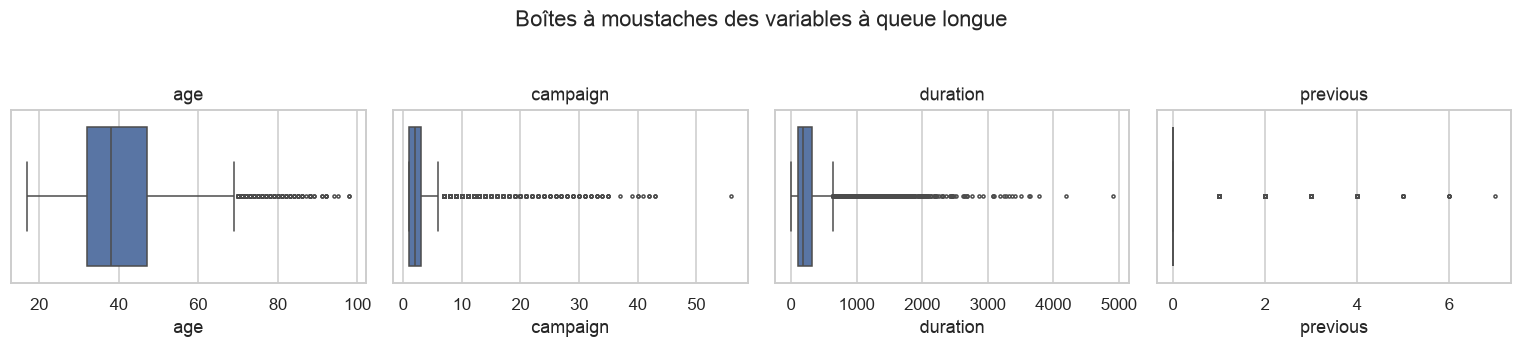

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, col in zip(axes, ["age", "campaign", "duration", "previous"]):
    sns.boxplot(x=df_raw[col], ax=ax, color="#4C72B0", fliersize=2)
    ax.set_title(col)
plt.suptitle("Boîtes à moustaches des variables à queue longue", y=1.05)
plt.tight_layout(); plt.savefig(FIG / "01_boxplots.png", bbox_inches="tight"); plt.show()

**Lecture et décisions :**
- `age` : les valeurs élevées (jusqu'à 98 ans) sont de **vrais clients seniors**, pas des erreurs → on les garde telles quelles.
- `campaign` : queue très longue (jusqu'à 56 appels). K-means étant sensible aux valeurs extrêmes, on **plafonne au 99ᵉ centile** (winsorisation) plutôt que de supprimer des clients.
- `pdays` : la valeur 999 n'est pas une durée mais un **code** (« jamais recontacté », 96 % des cas). On la remplace par un indicateur binaire `contacted_before`.
- `previous` : presque toujours 0 ; les valeurs non nulles sont informatives, on les garde.

Toutes ces règles sont codées dans `src/preprocessing.py` → fonction `clean()` (réutilisable).

In [9]:
df = pp.clean(df_raw, verbose=True)

n_initial                       : 41188
doublons_supprimes              : 12
unknown_job                     : 330 -> mode 'admin.'
unknown_marital                 : 80 -> mode 'married'
unknown_education               : 1730 -> mode 'university.degree'
unknown_housing                 : 990 -> mode 'yes'
unknown_loan                    : 990 -> mode 'no'
unknown_default                 : 8596 conservés (modalité)
campaign_plafond_p99            : 14.0
campaign_valeurs_plafonnees     : 406
n_final                         : 41176


## 3. Analyse exploratoire (EDA)
### 3.1 Statistiques descriptives

In [10]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41176.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41176.0,258.32,259.31,0.00,102.00,180.00,319.00,4918.00
campaign,41176.0,2.50,2.30,1.00,1.00,2.00,3.00,14.00
pdays,41176.0,962.46,186.94,0.00,999.00,999.00,999.00,999.00
previous,41176.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41176.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41176.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41176.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41176.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41176.0,5167.03,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


In [11]:
df.describe(include="object").T

,count,unique,top,freq
job,41176,11,admin.,10749
marital,41176,3,married,25001
education,41176,7,university.degree,13894
default,41176,3,no,32577
housing,41176,2,yes,22561
loan,41176,2,no,34928
contact,41176,2,cellular,26135
month,41176,10,may,13767
day_of_week,41176,5,thu,8618
poutcome,41176,3,nonexistent,35551


### 3.2 Distributions des variables numériques

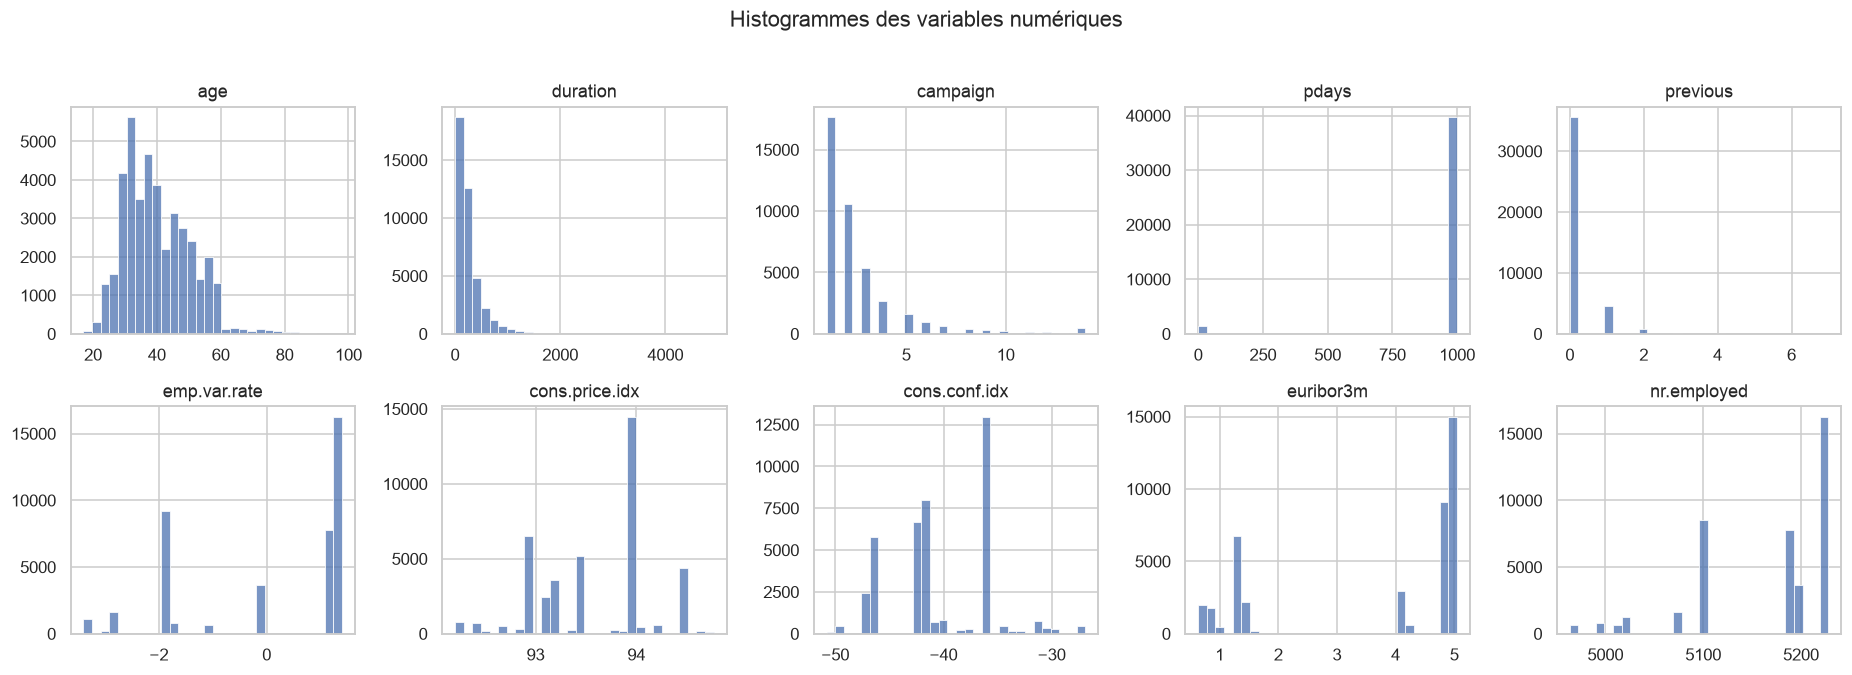

In [12]:
num_cols = df.select_dtypes("number").columns
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4C72B0")
    ax.set_title(col); ax.set_xlabel(""); ax.set_ylabel("")
plt.suptitle("Histogrammes des variables numériques", y=1.02)
plt.tight_layout(); plt.savefig(FIG / "01_histogrammes.png", bbox_inches="tight"); plt.show()

- `age` : distribution étalée à droite, centrée autour de 38 ans.
- `campaign`, `previous`, `duration` : très asymétriques (beaucoup de petites valeurs).
- Indicateurs économiques : **multimodaux**. Ils ne prennent qu'un petit nombre de valeurs (une par période), ce qui annonce déjà des groupes liés au contexte économique.

### 3.3 Répartition des variables catégorielles

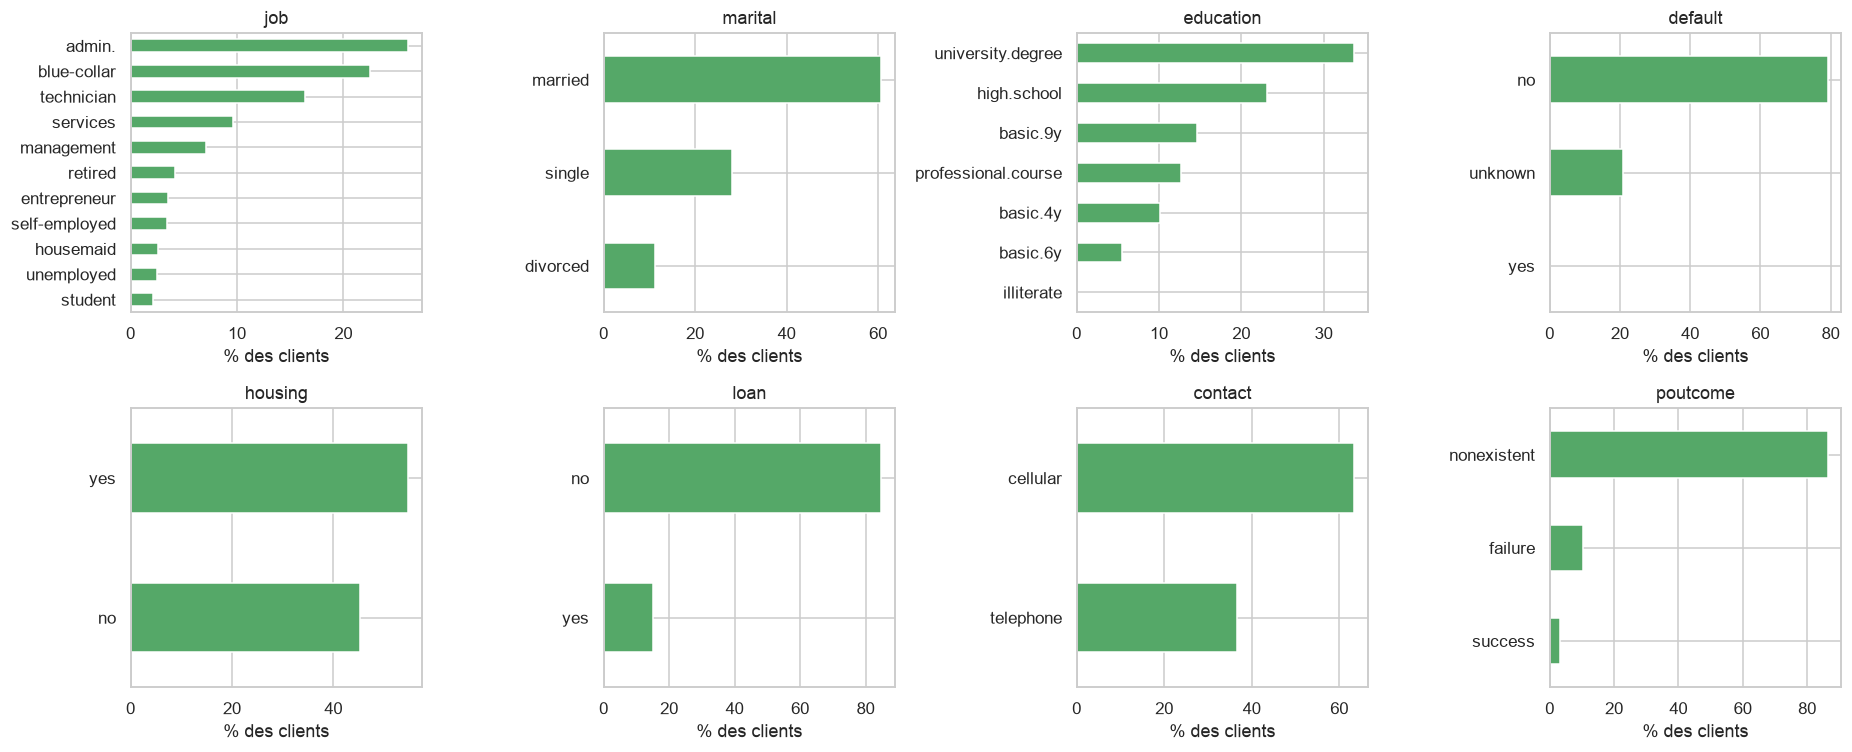

In [13]:
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "poutcome"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    (df[col].value_counts(normalize=True) * 100).sort_values().plot.barh(ax=ax, color="#55A868")
    ax.set_title(col); ax.set_xlabel("% des clients"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIG / "01_categorielles.png", bbox_inches="tight"); plt.show()

Les variables binaires rares (`loan = yes`, `poutcome = success`, `contacted_before = yes`) sont **asymétriques** : partager un « oui » est beaucoup plus informatif que partager un « non ». Ce point guidera le choix Hamming / Jaccard au Jour 2.

### 3.4 Corrélations

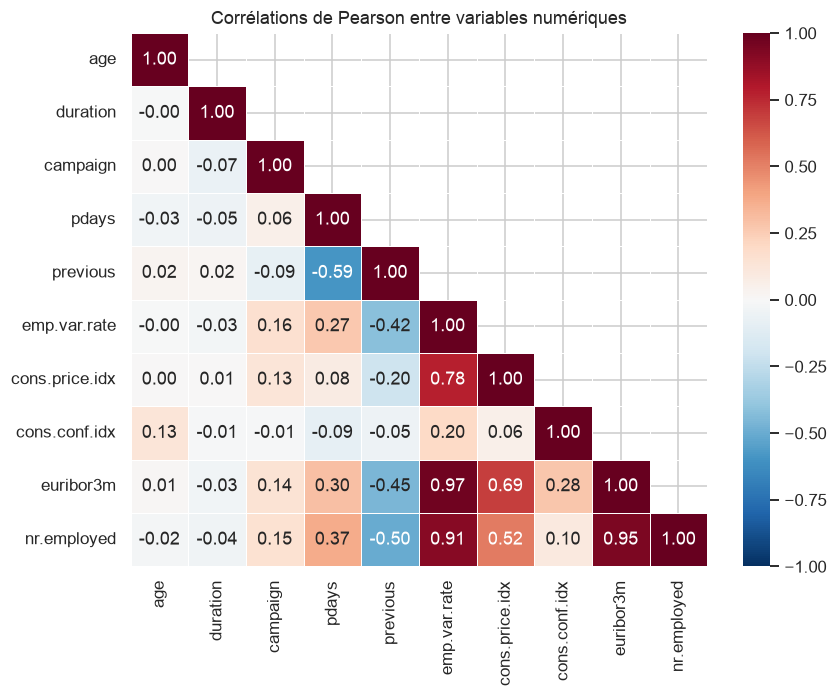

In [14]:
corr = df[num_cols].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), linewidths=.5)
plt.title("Corrélations de Pearson entre variables numériques")
plt.tight_layout(); plt.savefig(FIG / "01_correlations.png", bbox_inches="tight"); plt.show()

**Constat majeur** : `emp.var.rate`, `euribor3m` et `nr.employed` sont corrélées à plus de 0,90. Elles mesurent la même chose (la conjoncture). Les garder toutes les trois reviendrait à **compter trois fois** la même information dans les distances.

### 3.5 Nuages de points

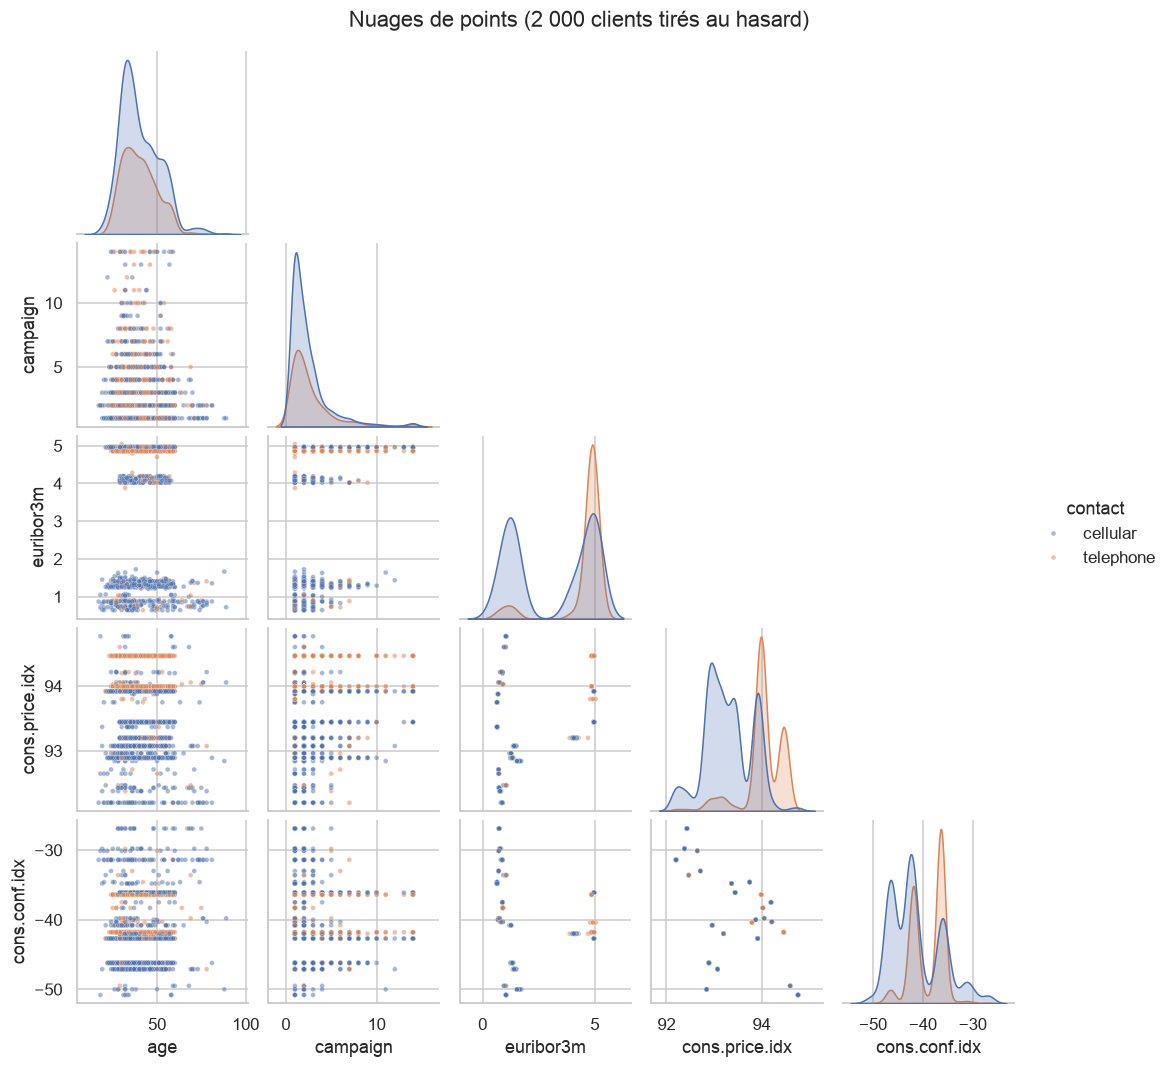

In [15]:
pair_cols = ["age", "campaign", "euribor3m", "cons.price.idx", "cons.conf.idx"]
g = sns.pairplot(df.sample(2000, random_state=SEED)[pair_cols + ["contact"]], hue="contact",
                 plot_kws={"s": 10, "alpha": .5}, height=1.9, corner=True)
g.fig.suptitle("Nuages de points (2 000 clients tirés au hasard)", y=1.02)
plt.savefig(FIG / "01_pairplot.png", bbox_inches="tight"); plt.show()

Les nuages mêlant deux indicateurs économiques forment des **paquets isolés** : chaque paquet correspond à une période de la campagne. Le canal de contact (`telephone` / `cellular`) est lui aussi lié à la période. Les variables socio-démographiques (âge…) ne montrent en revanche aucun groupe évident à l'œil nu.

## 4. Variables actives et variables illustratives

Toutes les variables ne doivent pas servir à **construire** les groupes. On distingue :
- les variables **actives**, utilisées par les algorithmes ;
- les variables **illustratives**, écartées du calcul mais gardées pour **décrire** les segments au Jour 5.

| Variable écartée | Raison |
|---|---|
| `duration` | Connue seulement **après** l'appel : inutilisable pour cibler une campagne à l'avance. Elle est de plus quasi déterministe de `y` (un appel de 0 s donne toujours `no`), ce qui ferait entrer la cible par la fenêtre. |
| `emp.var.rate`, `nr.employed` | Redondantes avec `euribor3m` (corrélation > 0,90). On garde un seul représentant. |
| `pdays` | Remplacée par l'indicateur `contacted_before`. |
| `month`, `day_of_week` | Décrivent le **calendrier de la campagne**, pas le client ; `month` est en outre un doublon du contexte économique. |
| `y` | Vérité terrain, interdite à l'entraînement. |

Il reste **15 variables actives** : 6 numériques et 9 catégorielles.

In [16]:
print("Numériques actives   :", pp.ACTIVE_NUM)
print("Catégorielles actives:", pp.ACTIVE_CAT)
print("Illustratives        :", pp.ILLUSTRATIVE)
X_mixed_full, illus_full, y_full = pp.split_roles(df)

Numériques actives   : ['age', 'campaign', 'previous', 'cons.price.idx', 'cons.conf.idx', 'euribor3m']
Catégorielles actives: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'contacted_before']
Illustratives        : ['duration', 'month', 'day_of_week', 'pdays', 'emp.var.rate', 'nr.employed']


## 5. Les deux représentations des données
### (a) One-hot + standardisation
- Variables catégorielles → indicatrices 0/1 (*one-hot*).
- Variables numériques → centrées-réduites : $z = \dfrac{x - \mu}{\sigma}$, pour que l'âge (dizaines) ne pèse pas plus que l'Euribor (unités).

Cette représentation est destinée aux méthodes **euclidiennes** : K-means, GMM, Ward, DBSCAN, PCA.

In [17]:
X_a_full, prep = pp.encode(X_mixed_full)
print("Représentation (a) :", X_a_full.shape)
check = X_a_full[pp.ACTIVE_NUM].agg(["mean", "std"]).T.round(3)
print("\nVérification de la standardisation (moyenne ≈ 0, écart-type ≈ 1) :")
print(check)
X_a_full.head(3)

Représentation (a) : (41176, 37)

Vérification de la standardisation (moyenne ≈ 0, écart-type ≈ 1) :
                mean  std
age              0.0  1.0
campaign         0.0  1.0
previous         0.0  1.0
cons.price.idx   0.0  1.0
cons.conf.idx   -0.0  1.0
euribor3m       -0.0  1.0


,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,education_basic.4y,education_basic.6y,education_basic.9y,education_high.school,education_illiterate,education_professional.course,education_university.degree,default_no,default_unknown,default_yes,housing_yes,loan_yes,contact_telephone,poutcome_failure,poutcome_nonexistent,poutcome_success,contacted_before_yes
0,1.533143,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,1.629107,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
2,-0.290177,-0.651907,-0.349551,0.722628,0.886568,0.712463,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0


### (b) Données mixtes brutes
On garde les variables dans leur nature d'origine (nombres et chaînes). Cette représentation est destinée à la **distance de Gower** (K-medoids, CAH) et à **K-prototypes**, qui traitent chaque variable selon son type.

In [18]:
X_mixed_full.head(3)

,age,campaign,previous,cons.price.idx,cons.conf.idx,euribor3m,job,marital,education,default,housing,loan,contact,poutcome,contacted_before
0,56,1,0,93.994,-36.4,4.857,housemaid,married,basic.4y,no,no,no,telephone,nonexistent,no
1,57,1,0,93.994,-36.4,4.857,services,married,high.school,unknown,no,no,telephone,nonexistent,no
2,37,1,0,93.994,-36.4,4.857,services,married,high.school,no,yes,no,telephone,nonexistent,no


## 6. Échantillon aléatoire stratifié
Les méthodes à matrice de distances stockent $n^2$ valeurs : avec 41 176 clients, cela ferait 1,7 milliard de distances. Comme le demande le sujet, on travaille donc sur un **échantillon de 4 000 clients**.

La stratification porte sur `y` pour garder le même taux de souscription que dans la population. `y` sert uniquement au tirage : aucun algorithme ne la voit.

In [19]:
d = pp.prepare_all()            # tout le pipeline en une ligne (fonction réutilisable)
X_a, X_mixed, y = d["X_a"], d["X_mixed"], d["y"]
print("Échantillon :", X_a.shape)
pd.DataFrame({"population": y_full.value_counts(normalize=True).round(4),
              "échantillon": y.value_counts(normalize=True).round(4)})

Échantillon : (4000, 37)


,population,échantillon
y,,
no,0.8873,0.8872
yes,0.1127,0.1128


In [20]:
cmp = pd.DataFrame({"population": X_mixed_full[pp.ACTIVE_NUM].mean(),
                    "échantillon": X_mixed[pp.ACTIVE_NUM].mean()}).round(3)
cmp["écart relatif (%)"] = (100 * (cmp["échantillon"] / cmp["population"] - 1)).round(2)
cmp

,population,échantillon,écart relatif (%)
age,40.024,40.190,0.41
campaign,2.500,2.438,-2.48
previous,0.173,0.181,4.62
cons.price.idx,93.576,93.560,-0.02
cons.conf.idx,-40.503,-40.491,-0.03
euribor3m,3.621,3.621,0.00


L'échantillon reproduit fidèlement la population (écarts de moyenne inférieurs à quelques pour cent) : il est **représentatif**.

## 7. Réduction de dimension
### 7.1 PCA (analyse en composantes principales)
La PCA cherche les axes orthogonaux qui conservent le plus de variance. Elle est ajustée sur la population complète, représentation (a).

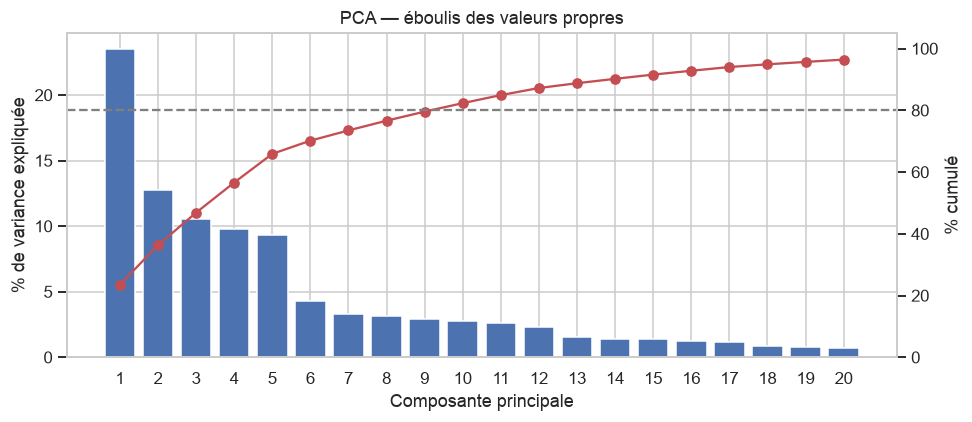

PC1 = 23.5%, PC2 = 12.8%  ->  plan principal = 36.3% de la variance
10 composantes pour atteindre 80 %, 14 pour 90 % (sur 37 colonnes)


In [21]:
pca = PCA(random_state=SEED).fit(X_a_full)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n80 = int(np.searchsorted(cum, 0.80) + 1)
n90 = int(np.searchsorted(cum, 0.90) + 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(1, 21), evr[:20] * 100, color="#4C72B0", label="variance par composante")
ax2 = ax.twinx()
ax2.plot(range(1, 21), cum[:20] * 100, "o-", color="#C44E52", label="variance cumulée")
ax2.axhline(80, ls="--", color="grey"); ax2.set_ylim(0, 105); ax2.grid(False)
ax.set_xlabel("Composante principale"); ax.set_ylabel("% de variance expliquée"); ax2.set_ylabel("% cumulé")
ax.set_xticks(range(1, 21))
plt.title("PCA — éboulis des valeurs propres")
plt.tight_layout(); plt.savefig(FIG / "01_pca_variance.png", bbox_inches="tight"); plt.show()
print(f"PC1 = {evr[0]:.1%}, PC2 = {evr[1]:.1%}  ->  plan principal = {cum[1]:.1%} de la variance")
print(f"{n80} composantes pour atteindre 80 %, {n90} pour 90 % (sur {X_a_full.shape[1]} colonnes)")

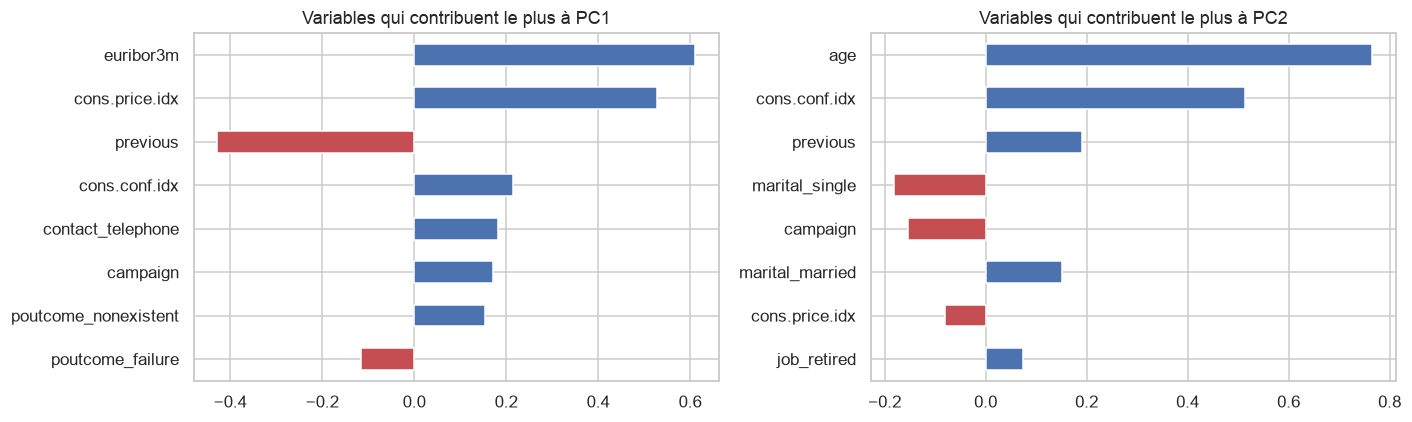

In [22]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X_a_full.columns, columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index)[:8][::-1]
    top.plot.barh(ax=ax, color=["#C44E52" if v < 0 else "#4C72B0" for v in top])
    ax.set_title(f"Variables qui contribuent le plus à {pc}")
plt.tight_layout(); plt.savefig(FIG / "01_pca_loadings.png", bbox_inches="tight"); plt.show()

**Interprétation des axes :**
- **PC1** oppose le contexte économique (`euribor3m`, `cons.price.idx`) à l'historique de contact (`previous`) : c'est un axe « conjoncture et relation passée avec la banque ».
- **PC2** est porté par l'`age` et la confiance des ménages (`cons.conf.idx`) : c'est un axe « profil du client ».

La variance est répartie sur beaucoup d'axes (il en faut une dizaine pour 80 %) : les données n'ont **pas** de structure simple en 2 dimensions, ce qui est habituel avec des indicatrices one-hot.

### 7.2 t-SNE et UMAP
La PCA est **linéaire**. t-SNE et UMAP sont **non linéaires** : ils cherchent à garder proches en 2D les points qui sont voisins dans l'espace d'origine. Ils servent à **visualiser**, pas à mesurer : les distances entre groupes éloignés n'y sont pas interprétables.

Ils sont calculés sur l'échantillon de 4 000 clients.

In [23]:
emb_file = OUT / "embeddings_sample.npz"
Z_pca = pca.transform(X_a)[:, :2]
if emb_file.exists():                      # déjà calculé : on relit (gain de temps)
    emb = np.load(emb_file)
    Z_tsne, Z_umap = emb["tsne"], emb["umap"]
else:
    Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(X_a)
    Z_umap = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(X_a)
    np.savez(emb_file, pca=Z_pca, tsne=Z_tsne, umap=Z_umap)
print("PCA :", Z_pca.shape, "| t-SNE :", Z_tsne.shape, "| UMAP :", Z_umap.shape)

PCA : (4000, 2) | t-SNE : (4000, 2) | UMAP : (4000, 2)


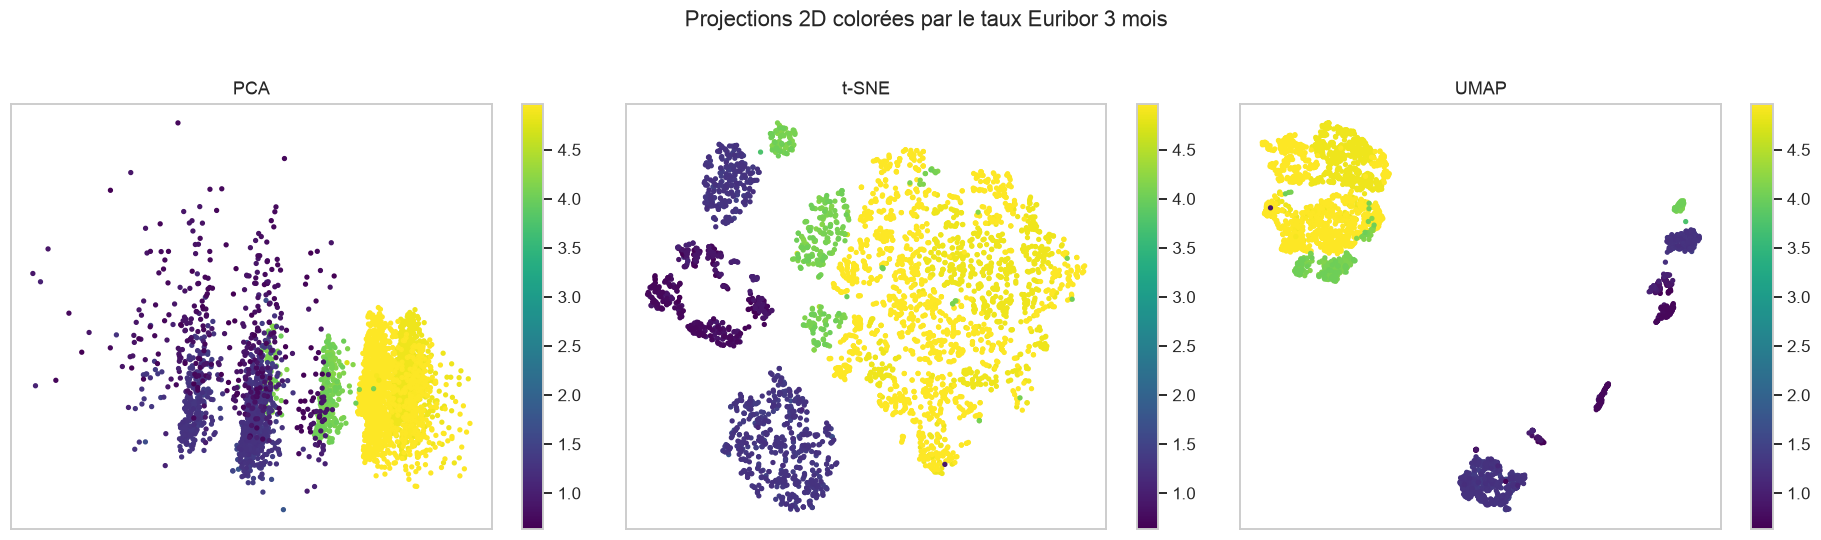

In [24]:
def plot_embeddings(color, title, cmap="viridis", categorical=False):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for ax, (name, Z) in zip(axes, [("PCA", Z_pca), ("t-SNE", Z_tsne), ("UMAP", Z_umap)]):
        if categorical:
            sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=color.values, s=8, ax=ax, linewidth=0, palette="Set1")
        else:
            sc = ax.scatter(Z[:, 0], Z[:, 1], c=color.values, s=6, cmap=cmap)
            plt.colorbar(sc, ax=ax)
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    return fig

fig = plot_embeddings(X_mixed["euribor3m"], "Projections 2D colorées par le taux Euribor 3 mois")
fig.savefig(FIG / "01_projections_euribor.png", bbox_inches="tight"); plt.show()

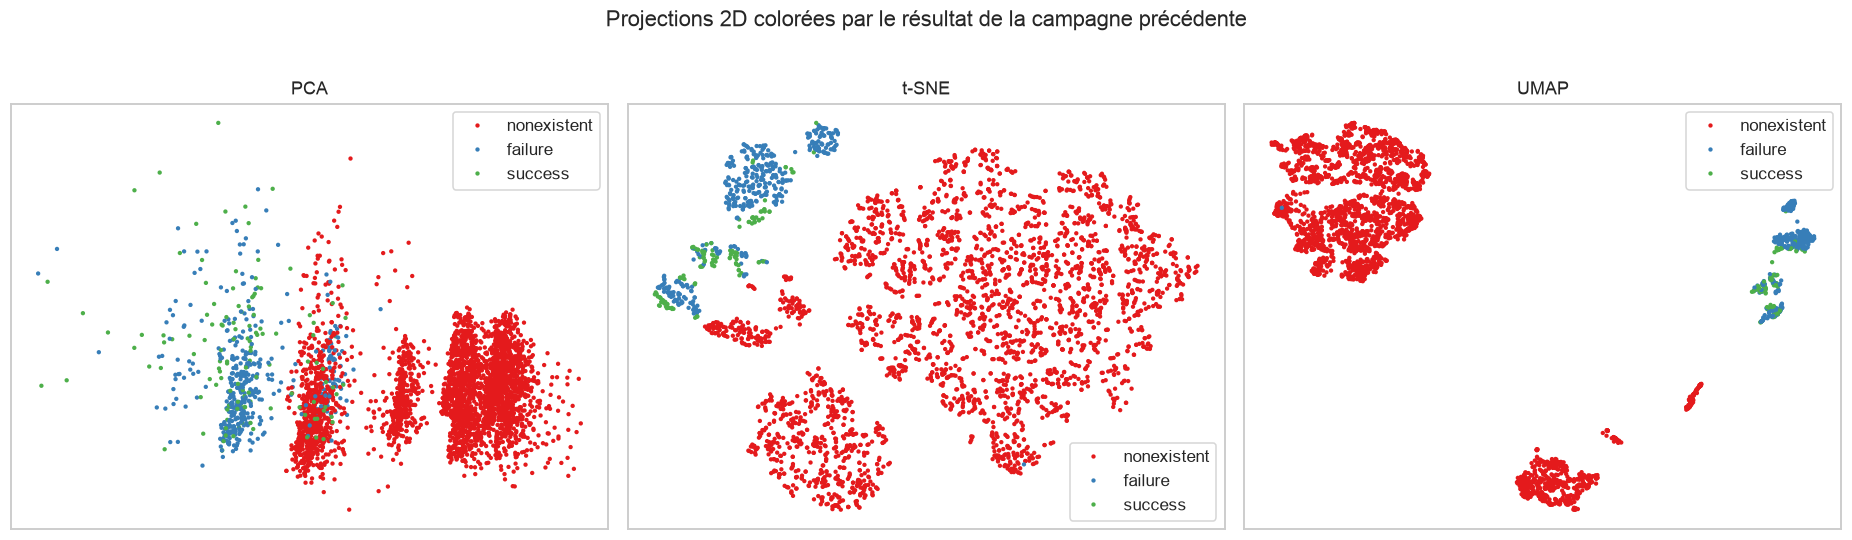

In [25]:
fig = plot_embeddings(X_mixed["poutcome"], "Projections 2D colorées par le résultat de la campagne précédente", categorical=True)
fig.savefig(FIG / "01_projections_poutcome.png", bbox_inches="tight"); plt.show()

**Ce que montrent les projections :**
- Sur la **PCA**, les clients s'organisent en bandes le long de PC1 : Euribor élevé d'un côté, Euribor bas de l'autre.
- **t-SNE** et **UMAP** révèlent quelques îlots, qui correspondent à des combinaisons de modalités (canal, résultat précédent, période). Les clients déjà démarchés (`poutcome` = `failure` ou `success`) forment des îlots bien à part.
- Aucune méthode ne montre 3 ou 4 « boules » nettes : il faut s'attendre à des **clusters qui se chevauchent** et à des silhouettes modestes.

## Bilan du Jour 1

| Point | Résultat |
|---|---|
| Données | 41 188 lignes → 41 176 après suppression de 12 doublons |
| Valeurs manquantes | `unknown` imputé par le mode (5 variables), conservé pour `default` |
| Valeurs aberrantes | `campaign` plafonnée au 99ᵉ centile ; `pdays` recodée en `contacted_before` |
| Variables actives | 15 (6 numériques + 9 catégorielles) |
| Représentation (a) | 37 colonnes, one-hot + standardisation |
| Représentation (b) | 15 colonnes mixtes pour Gower / K-prototypes |
| Échantillon | 4 000 clients, stratifié, représentatif |
| Réduction de dimension | PCA, t-SNE, UMAP calculés |

**Fonction de prétraitement réutilisable** : `src/preprocessing.py` → `prepare_all()` refait tout ce notebook en un appel. Les notebooks suivants commencent tous par cette ligne.

**Pistes pour la suite** : la structure dominante semble liée au contexte économique et à l'historique de contact. Reste à vérifier si les algorithmes la retrouvent, et avec combien de groupes.